# PlantVillage — Grad-CAM Explainability

This notebook uses Gradient-weighted Class Activation Mapping (Grad-CAM) to visualize the image regions that contribute to EfficientNetB0's disease predictions.

The objective is to make the image-classification model more interpretable by showing where the model is focusing when making a prediction.

### Objectives

- Load the selected EfficientNetB0 model
- Generate predictions for selected PlantVillage images
- Identify the model's predicted class
- Generate Grad-CAM activation maps
- Overlay the activation map on the original image
- Examine correct and incorrect predictions
- Investigate difficult disease classes

Grad-CAM provides a visualization of model activations and should not be interpreted as proof that the highlighted region is biologically or diagnostically correct.

In [41]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import load_model

In [42]:
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data" / "processed" / "plantvillage"
MODEL_DIR = PROJECT_ROOT / "models"

TEST_PATH = DATA_DIR / "test.csv"
MODEL_PATH = MODEL_DIR / "plantvillage_efficientnetb0.keras"

IMG_SIZE = (256, 256)

RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

In [43]:
model = load_model(MODEL_PATH)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 8, 8, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,187,927 (27.42 MB)

 Trainable params: 1,544,838 (5.89 MB)

 Non-trainable params: 2,553,411 (9.74 MB)

 Optimizer params: 3,089,678 (11.79 MB)

In [44]:
test_df = pd.read_csv(TEST_PATH)

print(f"Test images: {len(test_df):,}")
print(f"Number of classes: {test_df['class_id'].nunique()}")

Test images: 8,146
Number of classes: 38


In [45]:
class_ids = sorted(test_df["class_id"].unique())

class_to_index = {
    class_id: index
    for index, class_id in enumerate(class_ids)
}

index_to_class = {
    index: class_id
    for class_id, index in class_to_index.items()
}

test_df["label"] = test_df["class_id"].map(class_to_index)

NUM_CLASSES = len(class_ids)

target_names = [
    test_df.loc[
        test_df["class_id"] == index_to_class[i],
        "class_name"
    ].iloc[0]
    for i in range(NUM_CLASSES)
]

print("Classes:", NUM_CLASSES)

Classes: 38


In [46]:
def load_image(image_path):
    image_bytes = tf.io.read_file(str(image_path))
    image = tf.image.decode_jpeg(
        image_bytes,
        channels=3,
    )

    original_image = image.numpy()

    resized = tf.image.resize(
        image,
        IMG_SIZE,
    )

    resized = tf.cast(
        resized,
        tf.float32,
    )

    return original_image, resized

In [47]:
def predict_image(image):
    input_tensor = tf.expand_dims(
        image,
        axis=0,
    )

    predictions = model.predict(
        input_tensor,
        verbose=0,
    )[0]

    predicted_index = int(
        np.argmax(predictions)
    )

    confidence = float(
        predictions[predicted_index]
    )

    return predicted_index, confidence, predictions

In [48]:
sample_row = test_df.iloc[0]

image_path = PROJECT_ROOT / sample_row["image_path"]

original_image, processed_image = load_image(
    image_path
)

predicted_index, confidence, probabilities = (
    predict_image(processed_image)
)

predicted_class = target_names[predicted_index]
true_class = sample_row["class_name"]

print("True class:", true_class)
print("Predicted class:", predicted_class)
print(f"Confidence: {confidence:.4f}")

True class: Soybean___healthy
Predicted class: Soybean___healthy
Confidence: 1.0000


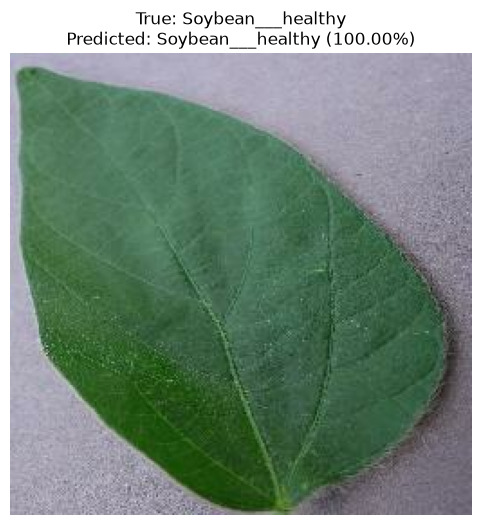

In [49]:
plt.figure(figsize=(6, 6))

plt.imshow(original_image.astype("uint8"))
plt.title(
    f"True: {true_class}\n"
    f"Predicted: {predicted_class} "
    f"({confidence:.2%})"
)

plt.axis("off")
plt.show()

In [50]:
for layer in model.layers[-30:]:
    print(
        layer.name,
        layer.__class__.__name__,
        layer.output.shape
    )

input_layer_1 InputLayer (None, 256, 256, 3)
efficientnetb0 Functional (None, 8, 8, 1280)
global_average_pooling2d GlobalAveragePooling2D (None, 1280)
dropout Dropout (None, 1280)
dense Dense (None, 38)


In [51]:
efficientnet_backbone = model.get_layer("efficientnetb0")

print(efficientnet_backbone)

<Functional name=efficientnetb0, built=True>


In [52]:
for layer in efficientnet_backbone.layers[-20:]:
    print(
        layer.name,
        layer.__class__.__name__,
        layer.output.shape
    )

block6d_project_conv Conv2D (None, 8, 8, 192)
block6d_project_bn BatchNormalization (None, 8, 8, 192)
block6d_drop Dropout (None, 8, 8, 192)
block6d_add Add (None, 8, 8, 192)
block7a_expand_conv Conv2D (None, 8, 8, 1152)
block7a_expand_bn BatchNormalization (None, 8, 8, 1152)
block7a_expand_activation Activation (None, 8, 8, 1152)
block7a_dwconv DepthwiseConv2D (None, 8, 8, 1152)
block7a_bn BatchNormalization (None, 8, 8, 1152)
block7a_activation Activation (None, 8, 8, 1152)
block7a_se_squeeze GlobalAveragePooling2D (None, 1152)
block7a_se_reshape Reshape (None, 1, 1, 1152)
block7a_se_reduce Conv2D (None, 1, 1, 48)
block7a_se_expand Conv2D (None, 1, 1, 1152)
block7a_se_excite Multiply (None, 8, 8, 1152)
block7a_project_conv Conv2D (None, 8, 8, 320)
block7a_project_bn BatchNormalization (None, 8, 8, 320)
top_conv Conv2D (None, 8, 8, 1280)
top_bn BatchNormalization (None, 8, 8, 1280)
top_activation Activation (None, 8, 8, 1280)


In [53]:
gradcam_layer = efficientnet_backbone.get_layer(
    "top_conv"
)

print(
    gradcam_layer.name,
    gradcam_layer.output.shape
)

top_conv (None, 8, 8, 1280)


In [54]:
efficientnet_backbone = model.get_layer("efficientnetb0")

gradcam_layer = efficientnet_backbone.get_layer("top_conv")

print("Grad-CAM layer:", gradcam_layer.name)
print("Grad-CAM output:", gradcam_layer.output.shape)

Grad-CAM layer: top_conv
Grad-CAM output: (None, 8, 8, 1280)


In [55]:
gradcam_backbone = tf.keras.models.Model(
    inputs=efficientnet_backbone.input,
    outputs=[
        gradcam_layer.output,
        efficientnet_backbone.output,
    ],
)

In [56]:
sample_images = tf.expand_dims(
    processed_image,
    axis=0,
)

conv_outputs, backbone_output = gradcam_backbone(
    sample_images
)

print("Conv output:", conv_outputs.shape)
print("Backbone output:", backbone_output.shape)

Conv output: (1, 8, 8, 1280)
Backbone output: (1, 8, 8, 1280)


In [57]:
def make_gradcam_heatmap(image, model, backbone, target_layer, class_index=None):
    """Create a Grad-CAM heatmap for the predicted class or an explicit class index."""
    image = tf.expand_dims(image, axis=0)
    grad_model = tf.keras.models.Model(
        inputs=backbone.input,
        outputs=[target_layer.output, backbone.output],
    )

    with tf.GradientTape() as tape:
        conv_outputs, backbone_output = grad_model(image, training=False)
        pooled_output = model.get_layer("global_average_pooling2d")(backbone_output)
        dropout_output = model.get_layer("dropout")(pooled_output, training=False)
        predictions = model.get_layer("dense")(dropout_output)
        if class_index is None:
            class_index = int(tf.argmax(predictions[0]).numpy())
        class_score = predictions[:, class_index]

    gradients = tape.gradient(class_score, conv_outputs)
    if gradients is None:
        raise RuntimeError(
            "Could not compute gradients for the selected layer. "
            "Check the model graph and Grad-CAM target layer."
        )
    pooled_gradients = tf.reduce_mean(gradients, axis=(1, 2))
    conv_outputs = conv_outputs[0]
    pooled_gradients = pooled_gradients[0]
    heatmap = tf.reduce_sum(conv_outputs * pooled_gradients, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + tf.keras.backend.epsilon())
    return heatmap.numpy(), int(class_index)


In [58]:
heatmap, predicted_index = make_gradcam_heatmap(
    processed_image,
    model,
    efficientnet_backbone,
    gradcam_layer,
)

print("Predicted class:", target_names[predicted_index])
print("Heatmap shape:", heatmap.shape)

Predicted class: Soybean___healthy
Heatmap shape: (8, 8)


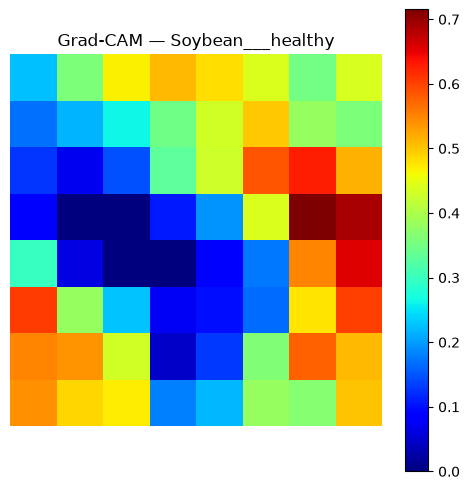

In [59]:
plt.figure(figsize=(6, 6))

plt.imshow(heatmap, cmap="jet")
plt.colorbar()

plt.title(
    f"Grad-CAM — {target_names[predicted_index]}"
)

plt.axis("off")
plt.show()

In [60]:
import cv2

heatmap_resized = cv2.resize(
    heatmap,
    (original_image.shape[1], original_image.shape[0])
)

heatmap_uint8 = np.uint8(
    255 * heatmap_resized
)

heatmap_color = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)

heatmap_color = cv2.cvtColor(
    heatmap_color,
    cv2.COLOR_BGR2RGB
)

overlay = (
    0.4 * heatmap_color
    + 0.6 * original_image
)

overlay = np.uint8(
    np.clip(overlay, 0, 255)
)

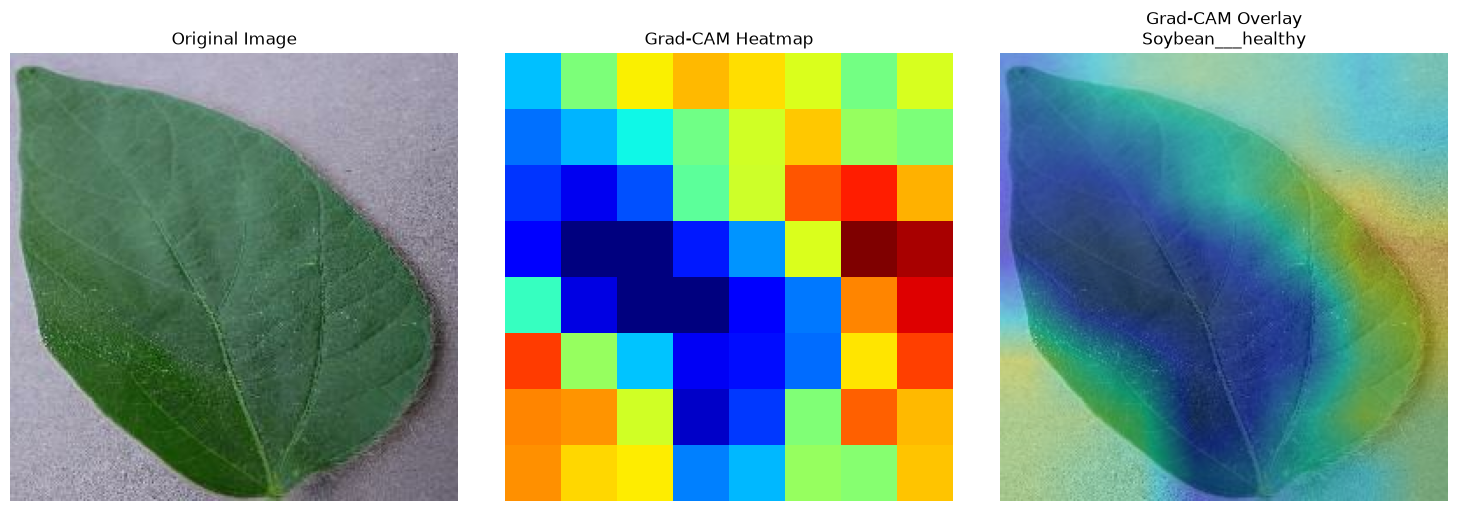

In [61]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(original_image.astype("uint8"))
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(heatmap, cmap="jet")
axes[1].set_title("Grad-CAM Heatmap")
axes[1].axis("off")

axes[2].imshow(overlay)
axes[2].set_title(
    f"Grad-CAM Overlay\n{target_names[predicted_index]}"
)
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [62]:
test_predictions = []

for _, row in test_df.iterrows():
    image_path = PROJECT_ROOT / row["image_path"]

    _, processed = load_image(image_path)

    predicted_index, confidence, _ = predict_image(processed)

    test_predictions.append({
        "image_path": row["image_path"],
        "true_class": row["class_name"],
        "true_label": row["label"],
        "predicted_class": target_names[predicted_index],
        "predicted_label": predicted_index,
        "confidence": confidence,
        "correct": predicted_index == row["label"],
    })

prediction_df = pd.DataFrame(test_predictions)

prediction_df.head()

,image_path,true_class,true_label,predicted_class,predicted_label,confidence,correct
0,PlantVillage-Dataset/raw/color/Soybean___healt...,Soybean___healthy,24,Soybean___healthy,24,1.000000,True
1,PlantVillage-Dataset/raw/color/Potato___health...,Potato___healthy,22,Potato___healthy,22,0.999916,True
2,PlantVillage-Dataset/raw/color/Corn_(maize)___...,Corn_(maize)___Common_rust_,8,Corn_(maize)___Common_rust_,8,1.000000,True
3,PlantVillage-Dataset/raw/color/Peach___Bacteri...,Peach___Bacterial_spot,16,Peach___Bacterial_spot,16,1.000000,True
4,PlantVillage-Dataset/raw/color/Tomato___Bacter...,Tomato___Bacterial_spot,28,Tomato___Bacterial_spot,28,0.999997,True


In [63]:
diseased_correct = prediction_df[
    (prediction_df["correct"])
    & (prediction_df["confidence"] >= 0.95)
    & (~prediction_df["true_class"].str.contains("healthy", case=False))
].sort_values(
    "confidence",
    ascending=False,
)

diseased_correct.head(10)

,image_path,true_class,true_label,predicted_class,predicted_label,confidence,correct
2,PlantVillage-Dataset/raw/color/Corn_(maize)___...,Corn_(maize)___Common_rust_,8,Corn_(maize)___Common_rust_,8,1.0,True
4770,PlantVillage-Dataset/raw/color/Apple___Apple_s...,Apple___Apple_scab,0,Apple___Apple_scab,0,1.0,True
4692,PlantVillage-Dataset/raw/color/Tomato___Leaf_M...,Tomato___Leaf_Mold,31,Tomato___Leaf_Mold,31,1.0,True
4693,PlantVillage-Dataset/raw/color/Tomato___Tomato...,Tomato___Tomato_Yellow_Leaf_Curl_Virus,35,Tomato___Tomato_Yellow_Leaf_Curl_Virus,35,1.0,True
4702,PlantVillage-Dataset/raw/color/Potato___Late_b...,Potato___Late_blight,21,Potato___Late_blight,21,1.0,True
4706,PlantVillage-Dataset/raw/color/Orange___Haungl...,Orange___Haunglongbing_(Citrus_greening),15,Orange___Haunglongbing_(Citrus_greening),15,1.0,True
4714,PlantVillage-Dataset/raw/color/Orange___Haungl...,Orange___Haunglongbing_(Citrus_greening),15,Orange___Haunglongbing_(Citrus_greening),15,1.0,True
4717,PlantVillage-Dataset/raw/color/Tomato___Tomato...,Tomato___Tomato_Yellow_Leaf_Curl_Virus,35,Tomato___Tomato_Yellow_Leaf_Curl_Virus,35,1.0,True
4719,PlantVillage-Dataset/raw/color/Tomato___Bacter...,Tomato___Bacterial_spot,28,Tomato___Bacterial_spot,28,1.0,True
4724,PlantVillage-Dataset/raw/color/Tomato___Tomato...,Tomato___Tomato_Yellow_Leaf_Curl_Virus,35,Tomato___Tomato_Yellow_Leaf_Curl_Virus,35,1.0,True


In [64]:
diseased_example = diseased_correct.iloc[8]

print("True class:", diseased_example["true_class"])
print("Predicted class:", diseased_example["predicted_class"])
print(
    f"Confidence: {diseased_example['confidence']:.4f}"
)

True class: Tomato___Bacterial_spot
Predicted class: Tomato___Bacterial_spot
Confidence: 1.0000


In [65]:
image_path = PROJECT_ROOT / diseased_example["image_path"]

original_image, processed_image = load_image(
    image_path
)

In [66]:
heatmap, predicted_index = make_gradcam_heatmap(
    processed_image,
    model,
    efficientnet_backbone,
    gradcam_layer,
)

print(
    "Predicted class:",
    target_names[predicted_index]
)
print(
    "Heatmap shape:",
    heatmap.shape
)

Predicted class: Tomato___Bacterial_spot
Heatmap shape: (8, 8)


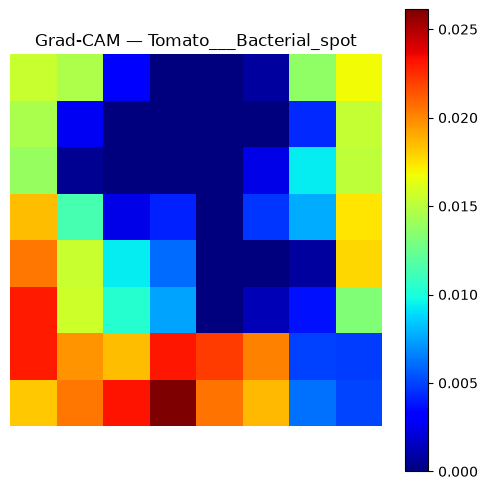

In [67]:
plt.figure(figsize=(6, 6))

plt.imshow(heatmap, cmap="jet")
plt.colorbar()

plt.title(
    f"Grad-CAM — {target_names[predicted_index]}"
)

plt.axis("off")
plt.show()

In [68]:
import cv2

heatmap_resized = cv2.resize(
    heatmap,
    (original_image.shape[1], original_image.shape[0])
)

heatmap_uint8 = np.uint8(
    255 * heatmap_resized
)

heatmap_color = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)

heatmap_color = cv2.cvtColor(
    heatmap_color,
    cv2.COLOR_BGR2RGB
)

overlay = (
    0.4 * heatmap_color
    + 0.6 * original_image
)

overlay = np.uint8(
    np.clip(overlay, 0, 255)
)

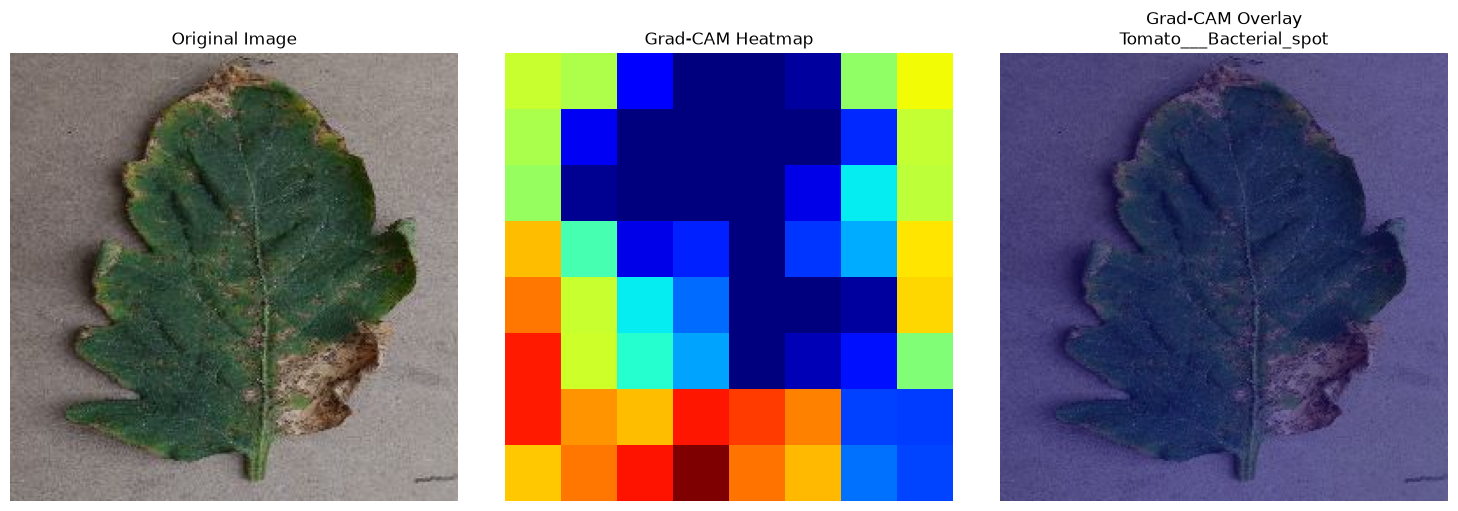

In [69]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(original_image.astype("uint8"))
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(heatmap, cmap="jet")
axes[1].set_title("Grad-CAM Heatmap")
axes[1].axis("off")

axes[2].imshow(overlay)
axes[2].set_title(
    f"Grad-CAM Overlay\n{target_names[predicted_index]}"
)
axes[2].axis("off")

plt.tight_layout()
plt.show()

## Systematic Grad-CAM case studies

The earlier cells demonstrate Grad-CAM on individual examples. This section selects reproducible cases from `prediction_df` instead of relying on a fixed row or `iloc[8]`. It covers:

1. A correctly classified healthy image
2. A correctly classified diseased image
3. A high-confidence incorrect prediction
4. Corn Gray Leaf Spot ↔ Northern Leaf Blight confusions
5. Tomato Spider Mites ↔ Target Spot confusions

Selection is based on the saved test-set predictions. If a requested case is absent from this test split, the helper reports that clearly rather than silently choosing an unrelated image.

> Grad-CAM highlights image features associated with a model score. It does not prove that the model used biologically valid evidence.


In [70]:
import cv2
# Normalize the prediction table and keep selection deterministic.
prediction_df = prediction_df.copy()
prediction_df["true_class"] = prediction_df["true_class"].astype(str)
prediction_df["predicted_class"] = prediction_df["predicted_class"].astype(str)
prediction_df["correct"] = prediction_df["correct"].astype(bool)
prediction_df = prediction_df.sort_values(
    ["confidence", "image_path"], ascending=[False, True]
).reset_index(drop=True)

print(f"Evaluated test images: {len(prediction_df):,}")
print(f"Correct predictions: {prediction_df['correct'].sum():,}")
print(f"Incorrect predictions: {(~prediction_df['correct']).sum():,}")


Evaluated test images: 8,146
Correct predictions: 8,051
Incorrect predictions: 95


In [71]:
def select_case(description, mask, *, prefer_high_confidence=True):
    """Return one deterministic matching prediction, or None if unavailable."""
    candidates = prediction_df.loc[mask].copy()
    if candidates.empty:
        print(f"Not found in this test split: {description}")
        return None
    candidates = candidates.sort_values(
        ["confidence", "image_path"],
        ascending=[not prefer_high_confidence, True],
    )
    row = candidates.iloc[0]
    print(f"{description} — selected from {len(candidates)} candidate(s)")
    print(f"  True:      {row['true_class']}")
    print(f"  Predicted: {row['predicted_class']}")
    print(f"  Confidence: {row['confidence']:.2%}")
    print(f"  Correct:   {row['correct']}")
    print(f"  Image:     {row['image_path']}")
    return row


def plot_gradcam_case(row, title=None, class_to_explain="predicted"):
    """Plot original, heatmap and overlay for a row from prediction_df."""
    if row is None:
        return
    image_path = PROJECT_ROOT / row["image_path"]
    original, processed = load_image(image_path)
    if class_to_explain == "predicted":
        target_index = int(row["predicted_label"])
    elif class_to_explain == "true":
        target_index = int(row["true_label"])
    else:
        raise ValueError("class_to_explain must be 'predicted' or 'true'")

    heatmap, _ = make_gradcam_heatmap(
        processed, model, efficientnet_backbone, gradcam_layer,
        class_index=target_index,
    )
    heatmap_resized = cv2.resize(
        heatmap, (original.shape[1], original.shape[0])
    )
    heatmap_uint8 = np.uint8(255 * np.clip(heatmap_resized, 0, 1))
    heatmap_color = cv2.cvtColor(
        cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET),
        cv2.COLOR_BGR2RGB,
    )
    overlay = np.uint8(np.clip(
        0.4 * heatmap_color + 0.6 * original.astype(np.float32), 0, 255
    ))

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(original.astype("uint8"))
    axes[0].set_title("Original")
    axes[1].imshow(heatmap, cmap="jet")
    axes[1].set_title("Grad-CAM heatmap")
    axes[2].imshow(overlay)
    axes[2].set_title("Overlay")
    for ax in axes:
        ax.axis("off")
    heading = title or "Grad-CAM case"
    fig.suptitle(
        f"{heading}\nTrue: {row['true_class']} | Predicted: {row['predicted_class']} "
        f"({row['confidence']:.1%}) | Explained: {target_names[target_index]}",
        y=1.05, fontsize=11,
    )
    plt.tight_layout()
    plt.show()


### Case 1 — Correctly classified healthy image

Correct healthy example — selected from 2250 candidate(s)
  True:      Apple___healthy
  Predicted: Apple___healthy
  Confidence: 100.00%
  Correct:   True
  Image:     PlantVillage-Dataset/raw/color/Apple___healthy/010125c0-e6f2-4f3d-b469-dd98ffecbb01___RS_HL 7948.JPG


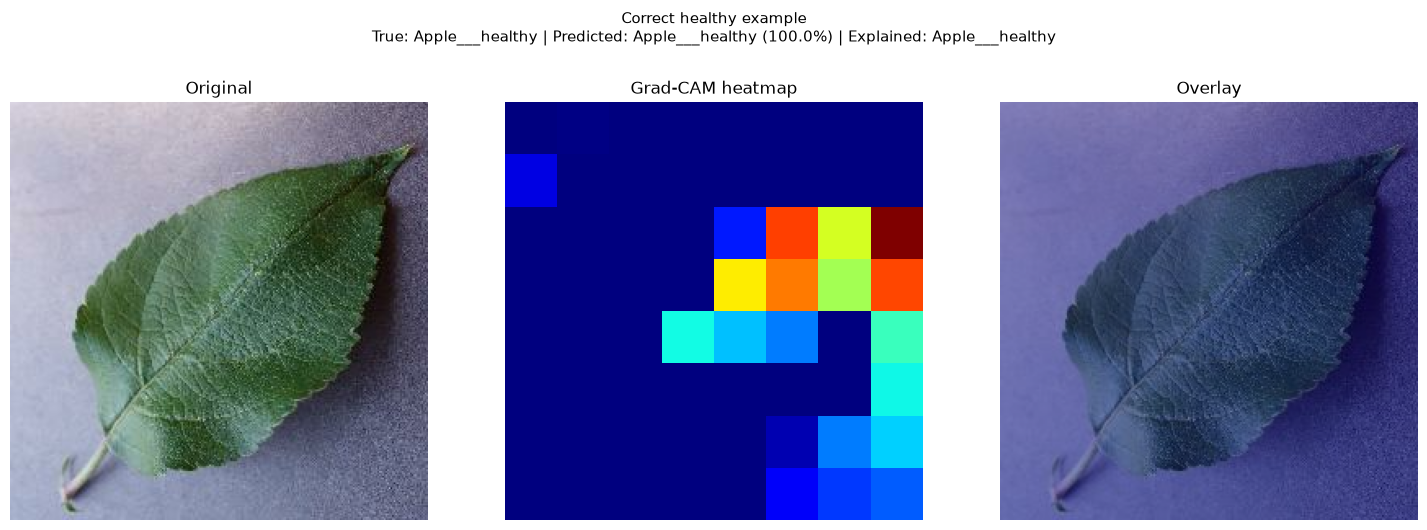

In [72]:
healthy_mask = prediction_df["true_class"].str.contains("healthy", case=False, na=False)
healthy_correct = select_case(
    "Correct healthy example",
    healthy_mask & prediction_df["correct"],
)
plot_gradcam_case(healthy_correct, "Correct healthy example")


### Case 2 — Correctly classified diseased image

Correct diseased example — selected from 5801 candidate(s)
  True:      Apple___Apple_scab
  Predicted: Apple___Apple_scab
  Confidence: 100.00%
  Correct:   True
  Image:     PlantVillage-Dataset/raw/color/Apple___Apple_scab/0340dc35-5215-48ab-8db7-06af99fcb358___FREC_Scab 2966.JPG


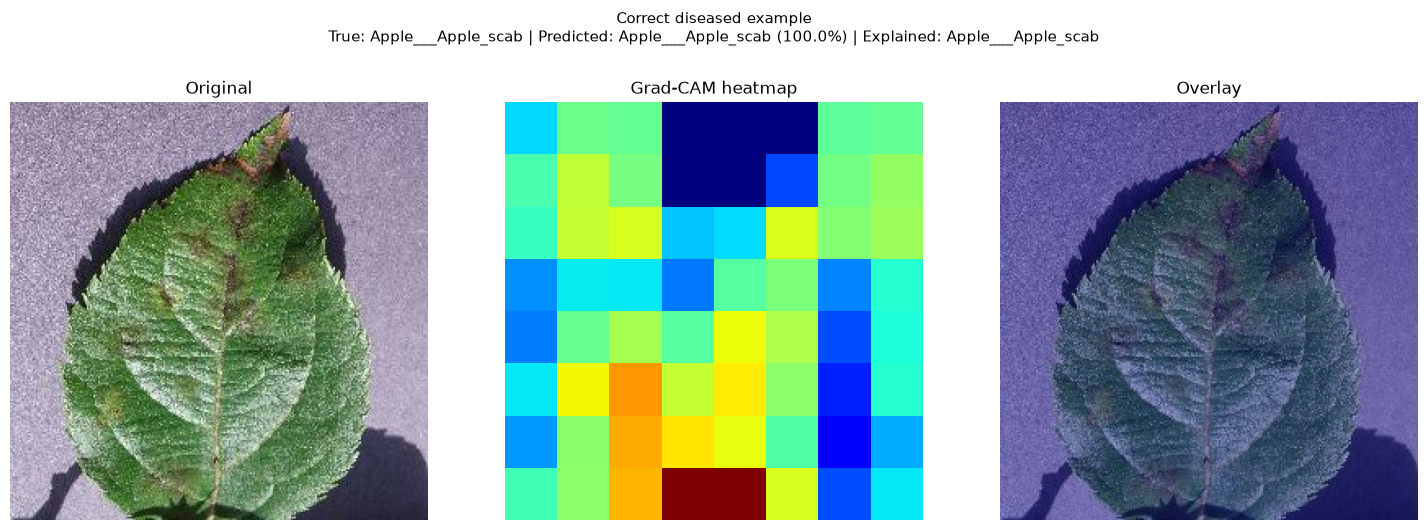

In [73]:
diseased_correct_case = select_case(
    "Correct diseased example",
    (~healthy_mask) & prediction_df["correct"],
)
plot_gradcam_case(diseased_correct_case, "Correct diseased example")


### Case 3 — High-confidence incorrect prediction

High-confidence incorrect example (confidence >= 80%) — selected from 54 candidate(s)
  True:      Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
  Predicted: Corn_(maize)___Northern_Leaf_Blight
  Confidence: 100.00%
  Correct:   False
  Image:     PlantVillage-Dataset/raw/color/Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot/ba462265-a5c8-4fa8-abb4-24054691eb16___RS_GLSp 3809.JPG


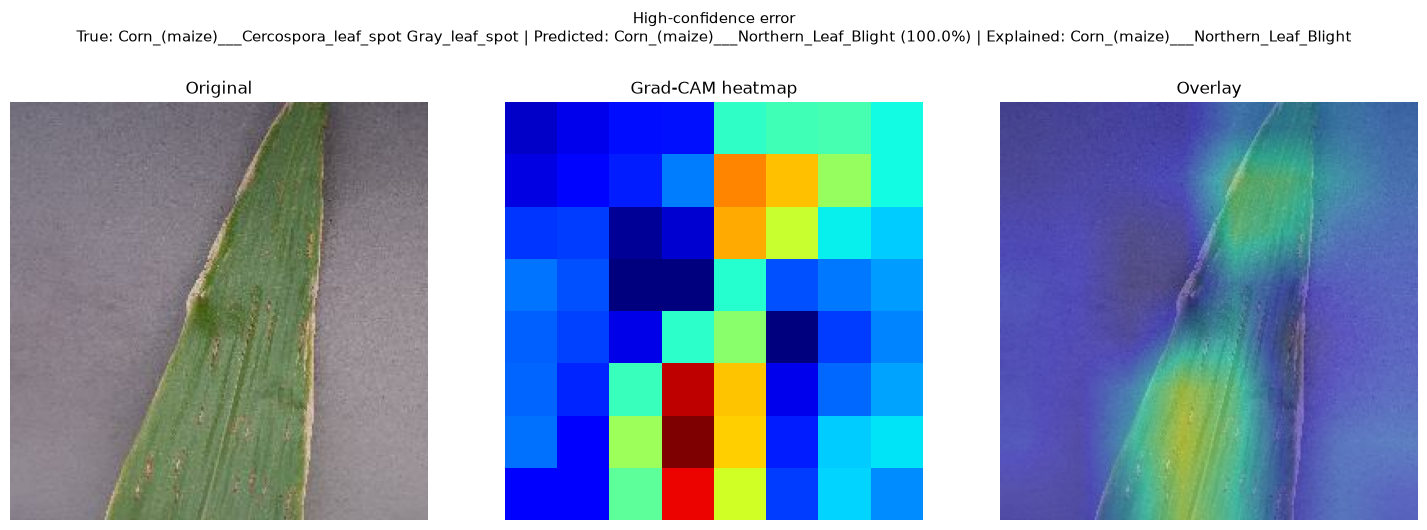

In [74]:
wrong_mask = ~prediction_df["correct"]
high_conf_wrong = prediction_df.loc[wrong_mask & (prediction_df["confidence"] >= 0.80)]
if high_conf_wrong.empty:
    # Fallback is still an incorrect prediction, chosen by highest confidence.
    high_conf_wrong_case = select_case(
        "Incorrect example (no incorrect prediction reached 80% confidence)",
        wrong_mask,
    )
else:
    high_conf_wrong_case = select_case(
        "High-confidence incorrect example (confidence >= 80%)",
        wrong_mask & (prediction_df["confidence"] >= 0.80),
    )
plot_gradcam_case(high_conf_wrong_case, "High-confidence error")


### Case 4 — Corn Gray Leaf Spot ↔ Northern Leaf Blight

Corn Gray Leaf Spot predicted as Northern Leaf Blight — selected from 6 candidate(s)
  True:      Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
  Predicted: Corn_(maize)___Northern_Leaf_Blight
  Confidence: 100.00%
  Correct:   False
  Image:     PlantVillage-Dataset/raw/color/Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot/ba462265-a5c8-4fa8-abb4-24054691eb16___RS_GLSp 3809.JPG


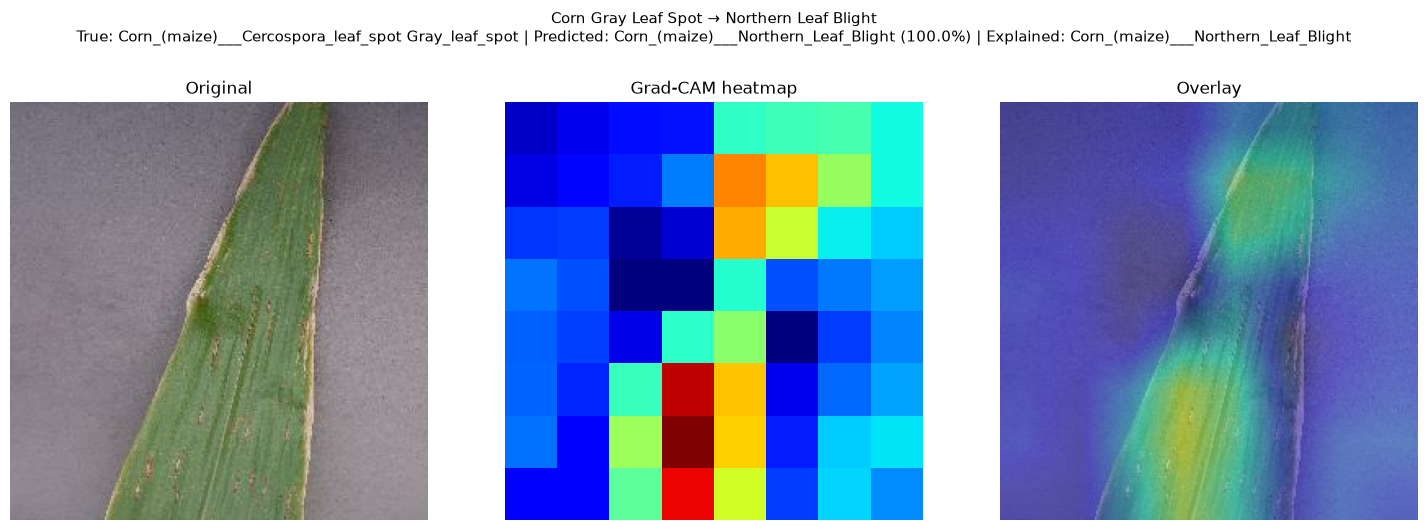

Corn Northern Leaf Blight predicted as Gray Leaf Spot — selected from 6 candidate(s)
  True:      Corn_(maize)___Northern_Leaf_Blight
  Predicted: Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
  Confidence: 99.98%
  Correct:   False
  Image:     PlantVillage-Dataset/raw/color/Corn_(maize)___Northern_Leaf_Blight/3fb57074-5e53-45e8-9219-bc0cee74f440___RS_NLB  4597.JPG


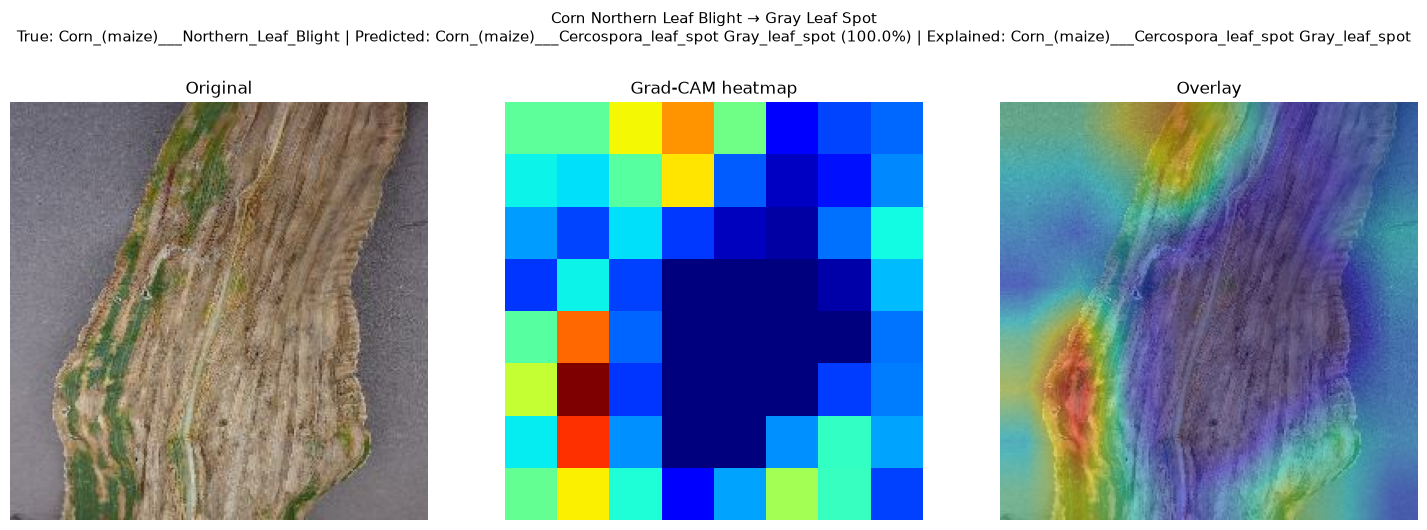

In [75]:
def class_name_matches(series, *terms):
    """Case-insensitive substring match, tolerant of underscores/spaces."""
    normalized = series.str.lower().str.replace("_", " ", regex=False)
    mask = pd.Series(True, index=series.index)
    for term in terms:
        mask &= normalized.str.contains(term.lower().replace("_", " "), regex=False, na=False)
    return mask

corn_gray_true = class_name_matches(prediction_df["true_class"], "corn", "gray leaf spot")
corn_nlb_true = class_name_matches(prediction_df["true_class"], "corn", "northern leaf blight")
corn_gray_pred = class_name_matches(prediction_df["predicted_class"], "corn", "gray leaf spot")
corn_nlb_pred = class_name_matches(prediction_df["predicted_class"], "corn", "northern leaf blight")

corn_gray_to_nlb = select_case(
    "Corn Gray Leaf Spot predicted as Northern Leaf Blight",
    corn_gray_true & corn_nlb_pred,
)
plot_gradcam_case(corn_gray_to_nlb, "Corn Gray Leaf Spot → Northern Leaf Blight")

corn_nlb_to_gray = select_case(
    "Corn Northern Leaf Blight predicted as Gray Leaf Spot",
    corn_nlb_true & corn_gray_pred,
)
plot_gradcam_case(corn_nlb_to_gray, "Corn Northern Leaf Blight → Gray Leaf Spot")


### Case 5 — Tomato Spider Mites ↔ Target Spot

Tomato Spider Mites predicted as Target Spot — selected from 7 candidate(s)
  True:      Tomato___Spider_mites Two-spotted_spider_mite
  Predicted: Tomato___Target_Spot
  Confidence: 95.72%
  Correct:   False
  Image:     PlantVillage-Dataset/raw/color/Tomato___Spider_mites Two-spotted_spider_mite/98c87686-b4a7-4dd4-a7fe-d9491e41a01f___Com.G_SpM_FL 9392.JPG


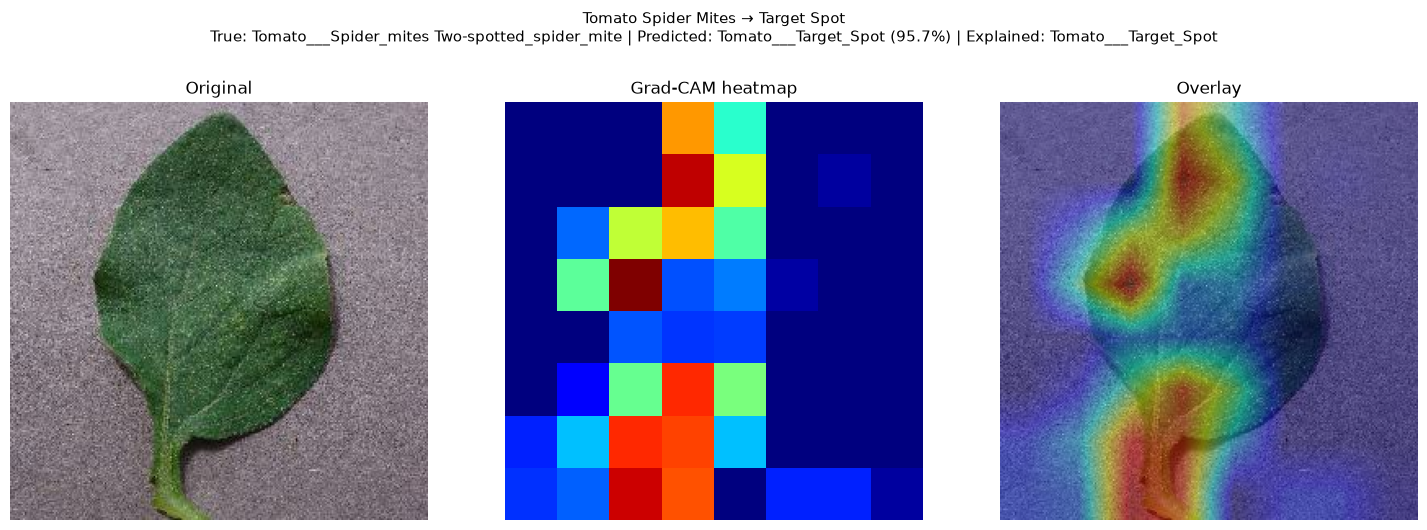

Tomato Target Spot predicted as Spider Mites — selected from 5 candidate(s)
  True:      Tomato___Target_Spot
  Predicted: Tomato___Spider_mites Two-spotted_spider_mite
  Confidence: 99.74%
  Correct:   False
  Image:     PlantVillage-Dataset/raw/color/Tomato___Target_Spot/63e1a2ad-a44f-4c4d-b123-417920259975___Com.G_TgS_FL 1035.JPG


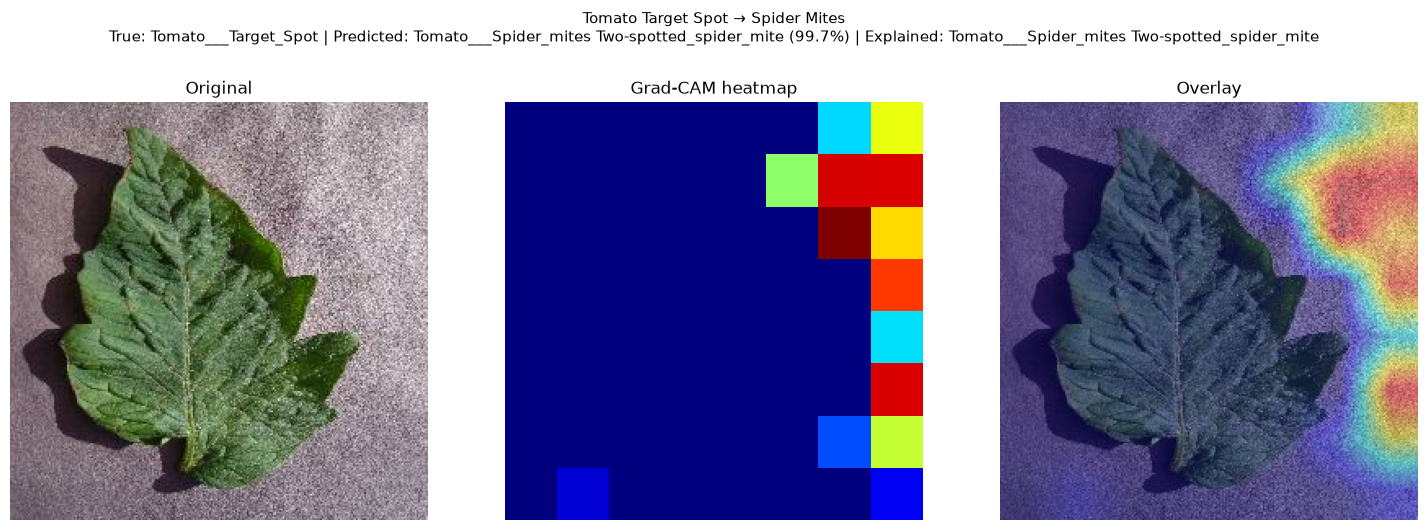

In [76]:
tomato_mites_true = class_name_matches(
    prediction_df["true_class"], "tomato", "spider mites"
) | class_name_matches(prediction_df["true_class"], "tomato", "two spotted spider mite")
tomato_target_true = class_name_matches(
    prediction_df["true_class"], "tomato", "target spot"
)
tomato_mites_pred = class_name_matches(
    prediction_df["predicted_class"], "tomato", "spider mites"
) | class_name_matches(prediction_df["predicted_class"], "tomato", "two spotted spider mite")
tomato_target_pred = class_name_matches(
    prediction_df["predicted_class"], "tomato", "target spot"
)

tomato_mites_to_target = select_case(
    "Tomato Spider Mites predicted as Target Spot",
    tomato_mites_true & tomato_target_pred,
)
plot_gradcam_case(tomato_mites_to_target, "Tomato Spider Mites → Target Spot")

tomato_target_to_mites = select_case(
    "Tomato Target Spot predicted as Spider Mites",
    tomato_target_true & tomato_mites_pred,
)
plot_gradcam_case(tomato_target_to_mites, "Tomato Target Spot → Spider Mites")


## Interpretation checklist

For each heatmap, record whether the strongest activation overlaps visible disease symptoms, healthy tissue, leaf boundaries, background, or image artifacts. Compare correct and incorrect cases carefully. A bright region only indicates relative activation for the selected class; it is not a causal explanation or a clinical/agronomic validation.

**Reproducibility note:** the examples are selected from the fixed test predictions and use confidence plus image-path tie-breaking. Results depend on the current model, test split, and class-index mapping.
